# Character-model training and evaluation

Use the existing `.venv` and EDA reports. Both character experiments and resume checkpoints are retained.
Whole-word inference and its 200-image test are in `04_hybrid_word_recognition.ipynb`.


## 1. Imports, paths and settings


In [ ]:
# These imports are also included in the portable inference module.
import math
import random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torchvision
from PIL import Image, ImageOps
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

PIPELINE_VERSION = 1


In [ ]:
# Training, metrics and experiment-tracking tools.
import copy
import gc
import hashlib
import json
import os
os.environ['MLFLOW_ALLOW_FILE_STORE'] = 'true'
import pickle
import platform
import shutil
import sys
import time
from importlib.metadata import version as package_version

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


In [ ]:
# Local paths; the saved experiment name is unchanged.
PROJECT_DIR = Path.cwd().resolve()
DATASET_DIR = PROJECT_DIR / 'BanglaLekha-Isolated'
EDA_DIR = PROJECT_DIR / 'reports' / 'eda'
EXPERIMENT_NAME = 'macos_resnet18_efficientnetb0_v1'
EXPERIMENT_DIR = PROJECT_DIR / 'training_runs' / EXPERIMENT_NAME

EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(PROJECT_DIR / 'cache' / 'torch'))

print('Python:', sys.executable)
print('Project:', PROJECT_DIR)


In [ ]:
# Small batches are suitable for a Mac with shared CPU/GPU memory.
CFG = {
    'seed': 42,
    'char_size': 128,
    'char_batch': 64,
    'char_epochs': 30,


    'encoder_lr': 0.0001,
    'head_lr': 0.0008,
    'weight_decay': 0.0001,
    'warmup_epochs': 2,
    'patience': 8,
    'label_smoothing': 0.05,

    'pretrained': True,
    'checkpoint_batches': 500,
    'checkpoint_seconds': 300,
    'benchmark_repeats': 100,
    'use_cache': True,
}


In [ ]:
# Use the Mac GPU when available; CPU remains supported.
DEVICE_NAME = 'auto'

if DEVICE_NAME == 'auto':
    DEVICE_NAME = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

DEVICE = torch.device(DEVICE_NAME)
print('Training device:', DEVICE)


## 2. Clean the EDA inventory and split by collection form


In [ ]:
def fingerprint(value):
    text = json.dumps(value, sort_keys=True, ensure_ascii=False)

    return hashlib.sha256(text.encode('utf-8')).hexdigest()


def save_json(value, path):
    # Replace completed files atomically instead of leaving partial JSON on interruption.
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')

    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    os.replace(temporary, path)


def frame_fingerprint(frame):
    columns = ['path', 'form_id', 'pixel_sha256', 'split', 'sample_id']
    columns += ['label']

    return hashlib.sha256(frame[columns].to_csv(index=False).encode()).hexdigest()


In [25]:
def grouped_split(frame, seed):
    # Entire collection forms stay together in approximately 70/15/15 partitions.
    frame = frame.copy().reset_index(drop=True)

    if frame['form_id'].nunique() < 7:
        raise ValueError('At least seven independent form/writer groups are required.')

    splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=seed)
    train_val, test = next(splitter.split(frame, groups=frame['form_id']))

    splitter = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=seed + 1)
    train, val = next(splitter.split(frame.iloc[train_val], groups=frame.iloc[train_val]['form_id']))

    frame['split'] = 'test'
    frame.loc[train_val[train], 'split'] = 'train'
    frame.loc[train_val[val], 'split'] = 'val'

    return frame


In [26]:
# Full EDA is required because sample audits cannot identify all duplicate leakage.
eda_summary = json.loads((EDA_DIR / 'summary.json').read_text())
assert eda_summary['scan_scope'] == 'full', 'Rerun EDA with FULL_SCAN=True.'

inventory = pd.read_csv(EDA_DIR / 'file_inventory.csv', dtype={'form_id': str})
quality = pd.read_csv(EDA_DIR / 'image_statistics.csv', dtype={'form_id': str})

assert inventory['path'].is_unique and quality['path'].is_unique
assert len(quality) + eda_summary['decode_errors'] == len(inventory)

columns = ['path', 'pixel_sha256', 'near_blank']
joined = inventory.merge(quality[columns], on='path', how='left', validate='one_to_one')

valid = joined['filename_ok'].eq(True)
valid &= joined['near_blank'].eq(False)
valid &= joined['pixel_sha256'].notna()

clean = joined.loc[valid].copy()
print('Filename/decoding/blank rows excluded:', len(joined) - len(clean))


Filename/decoding/blank rows excluded: 47


In [27]:
# Exclude every image in a conflicting-label duplicate group; do not guess its label.
hash_labels = clean.groupby('pixel_sha256')['class_id'].nunique()
conflicting_hashes = hash_labels.loc[hash_labels > 1].index

clean = clean.loc[~clean['pixel_sha256'].isin(conflicting_hashes)].copy()

# Retain one copy of each exact pixel pattern before splitting.
clean = clean.drop_duplicates('pixel_sha256').reset_index(drop=True)
clean['label'] = clean['class_id'].astype(int) - 1

char_frame = grouped_split(clean, CFG['seed'])
char_frame['sample_id'] = np.arange(len(char_frame))
char_fingerprint = frame_fingerprint(char_frame)

for split in ['train', 'val', 'test']:
    assert set(char_frame.loc[char_frame['split'] == split, 'label']) == set(range(84))

assert char_frame.groupby('form_id')['split'].nunique().max() == 1
assert char_frame['pixel_sha256'].is_unique
display(pd.crosstab(char_frame['class_id'], char_frame['split']))


split,test,train,val
class_id,,,
1,297,1378,297
2,296,1385,295
3,295,1382,295
4,295,1381,296
5,295,1384,296
...,...,...,...
80,289,1336,291
81,296,1374,297
82,296,1377,293


In [28]:
# Preserve the exact split and exclusions for later review.
manifest_path = EXPERIMENT_DIR / 'character_manifest.csv'

if manifest_path.exists():
    previous = pd.read_csv(manifest_path, dtype={'form_id': str})
    assert frame_fingerprint(previous) == char_fingerprint, 'Data/split changed; use a new experiment name.'

char_frame.to_csv(manifest_path, index=False)

excluded = inventory.loc[~inventory['path'].isin(char_frame['path'])]
excluded.to_csv(EXPERIMENT_DIR / 'excluded_character_images.csv', index=False)

save_json(CFG, EXPERIMENT_DIR / 'configuration.json')
print('Usable images:', len(char_frame))
print('Excluded rows:', len(excluded))
print(char_frame['split'].value_counts())


Usable images: 164763
Excluded rows: 1342
split
train    115294
test      24782
val       24687
Name: count, dtype: int64


## 3. Image preparation and a local pixel cache


In [29]:
def normalise_ink(image):
    # Composite transparent drawings onto white before determining their polarity.
    if image.mode in ['RGBA', 'LA'] or 'transparency' in image.info:
        rgba = image.convert('RGBA')
        background = Image.new('RGBA', rgba.size, 'white')
        image = Image.alpha_composite(background, rgba)

    pixels = np.array(ImageOps.exif_transpose(image).convert('L'), dtype=np.uint8)
    border = np.concatenate([pixels[0], pixels[-1], pixels[:, 0], pixels[:, -1]])

    if np.median(border) > 127:
        pixels = 255 - pixels

    y, x = np.where(pixels > 32)

    if len(x) == 0 or int(pixels.max()) - int(pixels.min()) < 16:
        raise ValueError('Blank image.')

    # Keep detached dots and vowel signs; do not remove connected components.
    return Image.fromarray(pixels[y.min():y.max() + 1, x.min():x.max() + 1])


In [30]:
def image_canvas(image, height, width):
    image = normalise_ink(image)
    margin = 4

    scale = min((height - 2 * margin) / image.height, (width - 2 * margin) / image.width)
    size = (max(1, round(image.width * scale)), max(1, round(image.height * scale)))
    image = image.resize(size, Image.Resampling.BILINEAR)

    canvas = Image.new('L', (width, height), 0)
    left = margin if width > height * 2 else (width - image.width) // 2
    top = (height - image.height) // 2
    canvas.paste(image, (left, top))

    return canvas


In [31]:
def canvas_tensor(canvas, augment=False, seed=0):
    rng = random.Random(int(seed))

    if augment:
        # Mild handwriting changes; flips would change character identities.
        canvas = TF.affine(
            canvas, angle=rng.uniform(-5, 5),
            translate=[rng.randint(-2, 2), rng.randint(-2, 2)],
            scale=rng.uniform(0.92, 1.04), shear=[rng.uniform(-4, 4), 0.0],
            interpolation=InterpolationMode.BILINEAR, fill=0,
        )

        if rng.random() < 0.2:
            canvas = TF.gaussian_blur(canvas, 3, rng.uniform(0.1, 0.6))

        canvas = TF.adjust_brightness(canvas, rng.uniform(0.8, 1.15))

    # Replicated grayscale accepts the ImageNet encoder's three input channels.
    tensor = TF.to_tensor(canvas).expand(3, -1, -1)

    return TF.normalize(tensor, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])


In [ ]:
from concurrent.futures import ThreadPoolExecutor


def _load_canvas(relative_path):
    with Image.open(DATASET_DIR / relative_path) as image:
        return np.asarray(image_canvas(image, CFG['char_size'], CFG['char_size']))


def build_character_cache(frame):
    key = fingerprint([frame['pixel_sha256'].tolist(), CFG['char_size'], PIPELINE_VERSION])[:16]
    folder = PROJECT_DIR / 'cache' / 'images'
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f'{key}.npy'
    shape = (len(frame), CFG['char_size'], CFG['char_size'])

    if path.exists():
        assert np.load(path, mmap_mode='r').shape == shape
        return path

    temporary = path.with_suffix('.tmp.npy')
    cache = np.lib.format.open_memmap(temporary, mode='w+', dtype='uint8', shape=shape)
    paths = frame['path'].tolist()

    # Threads avoid forking an already initialized PyTorch/Jupyter process on macOS.
    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 1)) as pool:
        for start in tqdm(range(0, len(paths), 512), desc='Caching images'):
            arrays = pool.map(_load_canvas, paths[start:start + 512])
            for offset, array in enumerate(arrays):
                cache[start + offset] = array

    cache.flush()
    del cache
    os.replace(temporary, path)
    return path


In [ ]:
# Existing completed runs do not need a new image cache for training.
context_path = EXPERIMENT_DIR / 'character_resume_context.json'
saved_context = json.loads(context_path.read_text()) if context_path.exists() else {}
all_completed = all(saved_context.get(name, {}).get('completed', False) and
                    (EXPERIMENT_DIR / 'character' / name / 'best_model.pt').is_file()
                    for name in ['resnet18', 'efficientnet_b0'])
CHAR_CACHE = build_character_cache(char_frame) if CFG['use_cache'] and not all_completed else None

print('Character cache:', CHAR_CACHE)


## 4. Dataset and deterministic batches


In [ ]:
class HandwritingDataset(Dataset):
    def __init__(self, frame, root, task='character', vocabulary=None, cache=None, augment=False):
        assert task == 'character'
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root)
        self.cache = np.load(cache, mmap_mode='r') if cache else None
        self.augment = augment
        self.epoch = 0
        self.sample_ids = self.frame['sample_id'].to_numpy()
        self.paths = self.frame['path'].tolist()
        self.labels = self.frame['label'].tolist()

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        sample_id = int(self.sample_ids[index])
        path = self.paths[index]

        if self.cache is not None:
            canvas = Image.fromarray(np.array(self.cache[sample_id]))
        else:
            with Image.open(self.root / path) as image:
                canvas = image_canvas(image, CFG['char_size'], CFG['char_size'])

        seed = CFG['seed'] + self.epoch * 1000003 + sample_id
        tensor = canvas_tensor(canvas, self.augment, seed)
        return tensor, int(self.labels[index]), '', path


In [ ]:
def collate_images(items):
    images, targets, texts, paths = zip(*items)
    return torch.stack(images), torch.tensor(targets), None, list(texts), list(paths)


NUM_WORKERS = 0  # Notebook-defined datasets stay in the macOS kernel process.
print('DataLoader workers:', NUM_WORKERS)

def make_loader(dataset, batch_size, epoch=0, start_batch=0, training=False):
    dataset.epoch = epoch
    indices = np.arange(len(dataset))

    if training:
        np.random.default_rng(CFG['seed'] + epoch).shuffle(indices)

    batches = [indices[i:i + batch_size].tolist() for i in range(0, len(indices), batch_size)]
    generator = torch.Generator().manual_seed(CFG['seed'] + epoch)

    loader = DataLoader(
        dataset, batch_sampler=batches[start_batch:],
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == 'cuda'),
        prefetch_factor=4 if NUM_WORKERS > 0 else None,
        collate_fn=collate_images, generator=generator,
    )

    return loader, len(batches)

## 5. ResNet-18 and EfficientNet-B0 model families


In [ ]:
def handwriting_encoder(name, pretrained=False):
    if name == 'resnet18':
        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        network = torchvision.models.resnet18(weights=weights)

        

        return nn.Sequential(*list(network.children())[:-2]), 512

    if name == 'efficientnet_b0':
        weights = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        network = torchvision.models.efficientnet_b0(weights=weights)

        

        return network.features, 1280

    raise ValueError(f'Unknown architecture: {name}')


In [37]:
class CharacterModel(nn.Module):
    def __init__(self, name, pretrained=False):
        super().__init__()

        self.encoder, channels = handwriting_encoder(name, pretrained)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.25),
            nn.Linear(channels, 84),
        )

    def forward(self, images):
        return self.head(self.encoder(images))


In [ ]:
def create_model(name, task='character', vocabulary=None, pretrained=False):
    if task != 'character':
        raise ValueError('This notebook supports the 84-class character models only.')
    return CharacterModel(name, pretrained)


## 6. Losses and metrics


In [ ]:
def empty_totals():
    return {'loss': 0.0, 'count': 0, 'correct': 0}


In [ ]:
def update_totals(totals, loss, targets, predictions, task):
    totals['loss'] += float(loss) * len(targets)
    totals['count'] += len(targets)
    totals['correct'] += sum(a == b for a, b in zip(targets, predictions))

    


def final_metrics(totals, task):
    assert totals['count'] > 0, 'Empty partition.'

    metrics = {
        'loss': totals['loss'] / totals['count'],
        'accuracy': totals['correct'] / totals['count'],
    }

      # One word per image.

    return metrics


In [ ]:
def forward_batch(run, batch):
    images, targets, lengths, texts, paths = batch
    logits = run['model'](images.to(DEVICE, non_blocking=True))

    loss = run['criterion'](logits, targets.to(DEVICE))
    truth = targets.tolist()
    predictions = logits.detach().argmax(-1).cpu().tolist()

    if not torch.isfinite(loss):
        raise FloatingPointError('Non-finite loss; inspect targets and learning rate.')

    return loss, truth, predictions, paths


## 7. Checkpoints and resumable training

Keep the same settings and experiment name to resume. Two atomic checkpoint slots
save batch position, optimizer, random states, partial metrics and best weights.
Work since the last checkpoint is repeated; different hardware may change results.


In [43]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


def capture_random_state():
    return {
        'python': random.getstate(),
        'numpy': np.random.get_state(),
        'torch': torch.get_rng_state(),
        'mps': torch.mps.get_rng_state() if torch.backends.mps.is_available() else None,
    }


def restore_random_state(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])

    if state['mps'] is not None and torch.backends.mps.is_available():
        torch.mps.set_rng_state(state['mps'])


In [44]:
def copy_to_cpu(value):
    # Store plain tensors, not notebook class instances or whole model objects.
    if torch.is_tensor(value):
        return value.detach().cpu().clone()

    if isinstance(value, dict):
        return {key: copy_to_cpu(item) for key, item in value.items()}

    if isinstance(value, (list, tuple)):
        copied = [copy_to_cpu(item) for item in value]
        return tuple(copied) if isinstance(value, tuple) else copied

    return copy.deepcopy(value)


def read_checkpoint(folder):
    paths = sorted(Path(folder).glob('last_[01].pt'), key=lambda p: p.stat().st_mtime_ns, reverse=True)

    for path in paths:
        try:
            # Full checkpoints contain Python RNG objects; load your own runs only.
            return torch.load(path, map_location='cpu', weights_only=False)
        except (OSError, RuntimeError, EOFError, ValueError, pickle.UnpicklingError):
            print('Unreadable checkpoint; trying the previous slot:', path.name)

    if paths:
        raise RuntimeError('Neither checkpoint slot could be read.')

    return None


In [45]:
def write_checkpoint(run):
    state = run['state']
    state['generation'] += 1
    state['weights'] = run['model'].state_dict()
    state['optimizer'] = run['optimizer'].state_dict()
    state['random_state'] = capture_random_state()

    slot = state['generation'] % 2
    path = run['folder'] / f'last_{slot}.pt'
    temporary = path.with_suffix('.pt.tmp')

    with temporary.open('wb') as handle:
        torch.save(copy_to_cpu(state), handle)
        handle.flush()
        os.fsync(handle.fileno())

    os.replace(temporary, path)


def fresh_state(signature):
    return {
        'signature': signature, 'epoch': 0, 'next_batch': 0, 'step': 0,
        'generation': 0, 'totals': empty_totals(), 'history': [],
        'best_score': -1e30, 'best_epoch': 0, 'best_weights': None,
        'bad_epochs': 0, 'completed': False, 'train_seconds': 0.0,
    }


In [ ]:
def saved_character_matches(name, frame, signature=None, check_versions=False):
    path = EXPERIMENT_DIR / 'character_resume_context.json'
    saved = json.loads(path.read_text()).get(name, {}) if path.exists() else {}
    matches = saved.get('settings') == CFG
    matches &= saved.get('data_fingerprint') == frame_fingerprint(frame)
    matches &= saved.get('pipeline_version') == PIPELINE_VERSION
    if signature is not None:
        matches &= saved.get('legacy_signature') == signature
    if check_versions:
        matches &= saved.get('torch') == str(torch.__version__)
        matches &= saved.get('torchvision') == str(torchvision.__version__)
    return bool(matches)


def completed_character_artifact(name, frame):
    folder = EXPERIMENT_DIR / 'character' / name
    context_path = EXPERIMENT_DIR / 'character_resume_context.json'
    context = json.loads(context_path.read_text()).get(name, {}) if context_path.exists() else {}
    if context.get('completed') and (folder / 'best_model.pt').is_file():
        if not saved_character_matches(name, frame):
            raise ValueError('Character settings/data changed; choose a new experiment name.')
        return folder / 'best_model.pt'
    return None


In [46]:
def run_identity(name, task, frame, initial_weights):
    initialization = None

    if initial_weights is not None:
        initialization = hashlib.sha256(Path(initial_weights).read_bytes()).hexdigest()

    return fingerprint({
        'architecture': name, 'task': task, 'settings': CFG,
        'data': frame_fingerprint(frame), 'initialization': initialization,
        'pipeline_version': PIPELINE_VERSION,
        'torch': str(torch.__version__), 'torchvision': str(torchvision.__version__),
    })


def make_optimizer(model):
    # Use a lower learning rate for the already pretrained encoder.
    head_parameters = [p for name, p in model.named_parameters() if not name.startswith('encoder.')]

    return torch.optim.AdamW([
        {'params': model.encoder.parameters(), 'lr': CFG['encoder_lr']},
        {'params': head_parameters, 'lr': CFG['head_lr']},
    ], weight_decay=CFG['weight_decay'], foreach=False)


In [ ]:
def start_run(name, task, frame, root, vocabulary, cache, initial_weights):
    folder = EXPERIMENT_DIR / task / name
    folder.mkdir(parents=True, exist_ok=True)
    state = read_checkpoint(folder)
    signature = fingerprint([run_identity(name, task, frame, initial_weights), vocabulary])

    if state is not None and state['signature'] != signature and not (initial_weights is None and not vocabulary and saved_character_matches(name, frame, state['signature'], check_versions=True)):
        raise ValueError('Settings, data or library versions changed; use a new experiment name.')

    seed_everything(CFG['seed'])
    pretrained = CFG['pretrained'] and state is None and initial_weights is None
    model = create_model(name, task, vocabulary, pretrained)

    if initial_weights is not None and state is None:
        saved = torch.load(initial_weights, map_location='cpu', weights_only=True)
        assert saved['task'] == 'character' and saved['architecture'] == name
        weights = {k.removeprefix('encoder.'): v for k, v in saved['state_dict'].items() if k.startswith('encoder.')}
        model.encoder.load_state_dict(weights, strict=True)

    model.to(DEVICE)
    optimizer = make_optimizer(model)

    if state is not None:
        model.load_state_dict(state['weights'])
        optimizer.load_state_dict(state['optimizer'])
        restore_random_state(state['random_state'])
        print('Resuming epoch/batch:', state['epoch'] + 1, state['next_batch'] + 1)

    run = {
        'name': name, 'task': task, 'folder': folder, 'model': model, 'optimizer': optimizer,
        'state': state if state is not None else fresh_state(signature),
        'vocabulary': vocabulary, 'fingerprint': frame_fingerprint(frame),
        'epochs': CFG['char_epochs'],
        'batch_size': CFG['char_batch'],
    }

    return prepare_run_data(run, frame, root, cache)


In [ ]:
def prepare_run_data(run, frame, root, cache):
    task = run['task']
    vocabulary = run['vocabulary']

    run['train_data'] = HandwritingDataset(
        frame.loc[frame['split'] == 'train'], root, task, vocabulary, cache, augment=True,
    )
    run['val_data'] = HandwritingDataset(
        frame.loc[frame['split'] == 'val'], root, task, vocabulary, cache,
    )

    _, run['batches'] = make_loader(run['train_data'], run['batch_size'], training=True)
    assert run['batches'] > 0

    run['criterion'] = (
        nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
    )

    return run


In [49]:
def learning_rate_factor(run):
    # Reconstructing the schedule from the saved update count prevents resume drift.
    total = run['epochs'] * run['batches']
    warmup = min(CFG['warmup_epochs'] * run['batches'], max(1, total // 4))
    step = run['state']['step']

    if step < warmup:
        return (step + 1) / warmup

    progress = (step - warmup) / max(1, total - warmup)

    return 0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * progress))


def optimizer_update(run, batch):
    factor = learning_rate_factor(run)

    for group, rate in zip(run['optimizer'].param_groups, [CFG['encoder_lr'], CFG['head_lr']]):
        group['lr'] = rate * factor

    run['optimizer'].zero_grad(set_to_none=True)
    loss, truth, predictions, paths = forward_batch(run, batch)
    loss.backward()

    norm = nn.utils.clip_grad_norm_(run['model'].parameters(), max_norm=5.0)
    if not torch.isfinite(norm):
        raise FloatingPointError('Non-finite gradients; inspect data and learning rate.')

    run['optimizer'].step()

    return loss.item(), truth, predictions


In [50]:
def train_one_epoch(run):
    state = run['state']
    run['model'].train()

    loader, _ = make_loader(
        run['train_data'], run['batch_size'], epoch=state['epoch'],
        start_batch=state['next_batch'], training=True,
    )

    last_save = time.monotonic()
    description = f"{run['task']}/{run['name']} epoch {state['epoch'] + 1}"

    for batch_index, batch in enumerate(tqdm(loader, desc=description), start=state['next_batch']):
        started = time.monotonic()
        loss, truth, predictions = optimizer_update(run, batch)

        update_totals(state['totals'], loss, truth, predictions, run['task'])
        state['step'] += 1
        state['next_batch'] = batch_index + 1
        state['train_seconds'] += time.monotonic() - started

        batch_limit = state['step'] % CFG['checkpoint_batches'] == 0
        time_limit = time.monotonic() - last_save >= CFG['checkpoint_seconds']

        if batch_limit or time_limit:
            write_checkpoint(run)
            last_save = time.monotonic()


In [ ]:
@torch.inference_mode()
def evaluate_partition(run, dataset):
    run['model'].eval()
    loader, _ = make_loader(dataset, run['batch_size'])
    totals = empty_totals()
    records = []

    for batch in loader:
        loss, truth, predictions, paths = forward_batch(run, batch)
        update_totals(totals, loss.item(), truth, predictions, run['task'])

        records.extend([
            {'path': path, 'truth': target, 'prediction': prediction, 'correct': target == prediction}
            for path, target, prediction in zip(paths, truth, predictions)
        ])

    metrics = final_metrics(totals, run['task'])
    predictions = pd.DataFrame(records)

    metrics['macro_f1'] = f1_score(
        predictions['truth'], predictions['prediction'],
        labels=list(range(84)), average='macro', zero_division=0,
    )

    return metrics, predictions


In [ ]:
def complete_epoch(run, validation):
    state = run['state']
    training = final_metrics(state['totals'], run['task'])
    score = validation['macro_f1']

    if score > state['best_score'] + 1e-7:
        state['best_score'] = score
        state['best_epoch'] = state['epoch'] + 1
        state['best_weights'] = copy_to_cpu(run['model'].state_dict())
        state['bad_epochs'] = 0
    else:
        state['bad_epochs'] += 1

    row = {'epoch': state['epoch'] + 1, 'training_seconds': state['train_seconds']}
    row.update({f'train_{key}': value for key, value in training.items()})
    row.update({f'val_{key}': value for key, value in validation.items()})
    row['encoder_lr'] = run['optimizer'].param_groups[0]['lr']
    state['history'].append(row)

    state['epoch'] += 1
    state['next_batch'] = 0
    state['totals'] = empty_totals()
    state['completed'] = state['epoch'] >= run['epochs'] or state['bad_epochs'] >= CFG['patience']

    return row


In [ ]:
def export_best_weights(run):
    state = run['state']
    task = run['task']
    height = CFG['char_size']
    width = height

    metadata = {
        'format_version': PIPELINE_VERSION, 'architecture': run['name'], 'task': task,
        'vocabulary': run['vocabulary'], 'height': height, 'width': width,
        'class_ids': list(range(1, 85)),
        'best_epoch': state['best_epoch'], 'signature': state['signature'],
        'data_fingerprint': run['fingerprint'], 'whole_word_ready': False,
        'validation_score': state['best_score'],
        'selection_metric': 'macro_f1',
        'torch_version': str(torch.__version__), 'torchvision_version': str(torchvision.__version__),
        'normalization': 'NFC', 'precision': 'FP32',
    }

    path = run['folder'] / 'best_model.pt'
    temporary = path.with_suffix('.pt.tmp')
    torch.save({**metadata, 'state_dict': state['best_weights']}, temporary)
    os.replace(temporary, path)

    save_json(metadata, run['folder'] / 'model_metadata.json')

    record_character_context(run)
    return path


In [ ]:
def record_character_context(run):
    path = EXPERIMENT_DIR / 'character_resume_context.json'
    saved = json.loads(path.read_text()) if path.exists() else {}
    saved[run['name']] = {
        'legacy_signature': run['state']['signature'], 'settings': CFG,
        'data_fingerprint': run['fingerprint'], 'completed': run['state']['completed'],
        'torch': str(torch.__version__), 'torchvision': str(torchvision.__version__),
        'pipeline_version': PIPELINE_VERSION,
    }
    save_json(saved, path)


In [54]:
def log_environment(run):
    parameters = sum(p.numel() for p in run['model'].parameters())
    packages = ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'Pillow']

    environment = {
        'python': platform.python_version(), 'system': platform.system(),
        'machine': platform.machine(), 'device': str(DEVICE), 'parameters': parameters,
        'packages': {name: package_version(name) for name in packages},
    }

    save_json(environment, run['folder'] / 'environment.json')
    (run['folder'] / 'architecture.txt').write_text(str(run['model']), encoding='utf-8')
    mlflow.log_params({**CFG, 'architecture': run['name'], 'task': run['task']})
    mlflow.set_tags({'device': str(DEVICE), 'data_fingerprint': run['fingerprint']})


def log_history(run, row):
    # The checkpoint is authoritative if a CSV write is interrupted.
    path = run['folder'] / 'history.csv'
    temporary = path.with_suffix('.csv.tmp')
    pd.DataFrame(run['state']['history']).to_csv(temporary, index=False)
    os.replace(temporary, path)

    metrics = {key: float(value) for key, value in row.items() if key != 'epoch'}
    mlflow.log_metrics(metrics, step=row['epoch'])
    print(row)


In [ ]:
def train_model(name, task, frame, root, vocabulary=None, cache=None, initial_weights=None):
    if task != 'character':
        raise ValueError('Only character training is supported here.')
    completed = completed_character_artifact(name, frame) if initial_weights is None else None
    if completed is not None:
        print('Using completed character experiment:', name)
        return completed

    vocabulary = vocabulary or []
    run = start_run(name, task, frame, root, vocabulary, cache, initial_weights)
    state = run['state']

    mlflow.set_tracking_uri((EXPERIMENT_DIR / 'mlruns').resolve().as_uri())
    mlflow.set_experiment(f'{EXPERIMENT_NAME}-{task}')

    try:
        with mlflow.start_run(run_id=state.get('run_id'), run_name=name) as tracking:
            state['run_id'] = tracking.info.run_id
            log_environment(run)

            while not state['completed']:
                train_one_epoch(run)
                validation, _ = evaluate_partition(run, run['val_data'])
                row = complete_epoch(run, validation)

                write_checkpoint(run)
                log_history(run, row)

            pd.DataFrame(state['history']).to_csv(run['folder'] / 'history.csv', index=False)
            artifact = export_best_weights(run)
            mlflow.log_artifact(str(artifact), artifact_path='model')
            mlflow.log_artifact(str(run['folder'] / 'history.csv'))
            mlflow.log_artifact(str(run['folder'] / 'environment.json'))

    except KeyboardInterrupt:
        # Keep the last committed update; never save a half-finished backward pass.
        print('Stopped. Rerun with unchanged settings to resume the last checkpoint.')
        raise

    return artifact


## 8. Evaluation, plots and timing

Select the winner using validation macro F1. Test scores do not select the model.
Training inputs are augmented; validation is clean. Batch-1 latency excludes disk reads.


In [ ]:
class Predictor:
    def __init__(self, path, device='cpu'):
        self.saved = torch.load(path, map_location='cpu', weights_only=True)
        assert self.saved['format_version'] == PIPELINE_VERSION

        self.device = torch.device(device)
        self.model = create_model(
            self.saved['architecture'], self.saved['task'], self.saved['vocabulary'],
        )
        self.model.load_state_dict(self.saved['state_dict'], strict=True)
        self.model.to(self.device).eval()

    def prepare(self, image):
        if isinstance(image, (str, Path)):
            with Image.open(image) as opened:
                image = opened.copy()

        canvas = image_canvas(image, self.saved['height'], self.saved['width'])

        return canvas_tensor(canvas).unsqueeze(0).to(self.device)

    @torch.inference_mode()
    def predict_character_id(self, image):
        if self.saved['task'] != 'character':
            raise ValueError('Load a character model for character classification.')

        return int(self.model(self.prepare(image)).argmax(-1).item()) + 1



In [ ]:
def plot_learning(folder, task):
    history = pd.read_csv(Path(folder) / 'history.csv')
    names = ['loss', 'accuracy']
    fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 4))

    for ax, name in zip(axes, names):
        ax.plot(history['epoch'], history[f'train_{name}'], label='Train (augmented)')
        ax.plot(history['epoch'], history[f'val_{name}'], label='Validation (clean)')
        ax.set(xlabel='Epoch', ylabel=name, title=name)
        ax.legend()
        ax.grid(alpha=0.2)

    fig.tight_layout()
    fig.savefig(Path(folder) / 'training_curves.png', dpi=160)
    plt.show()
    plt.close(fig)


In [ ]:
def save_classification_report(predictions, task, folder):
    labels = list(range(84))
    names = [f'class_{i + 1:02d}' for i in labels]

    report = classification_report(
        predictions['truth'], predictions['prediction'], labels=labels,
        target_names=names, output_dict=True, zero_division=0,
    )
    table = pd.DataFrame(report).T
    table.to_csv(Path(folder) / 'classification_report.csv', encoding='utf-8-sig')

    text = classification_report(
        predictions['truth'], predictions['prediction'], labels=labels,
        target_names=names, zero_division=0,
    )
    (Path(folder) / 'classification_report.txt').write_text(text, encoding='utf-8')

    return table


In [59]:
def plot_confusion(predictions, folder):
    labels = list(range(84))
    matrix = confusion_matrix(predictions['truth'], predictions['prediction'], labels=labels)
    normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)

    pd.DataFrame(matrix, index=range(1, 85), columns=range(1, 85)).to_csv(Path(folder) / 'confusion_matrix.csv')

    fig, ax = plt.subplots(figsize=(12, 10))
    picture = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    ticks = np.arange(0, 84, 4)
    ax.set(xticks=ticks, yticks=ticks, xticklabels=ticks + 1, yticklabels=ticks + 1,
           xlabel='Predicted class ID', ylabel='True class ID', title='Row-normalized confusion matrix')
    fig.colorbar(picture, ax=ax)
    fig.tight_layout()
    fig.savefig(Path(folder) / 'confusion_matrix.png', dpi=160)
    plt.show()
    plt.close(fig)

    pairs = [(int(matrix[i, j]), i + 1, j + 1) for i in labels for j in labels if i != j]
    pd.DataFrame(sorted(pairs, reverse=True)[:30], columns=['count', 'true_class', 'predicted_class']).to_csv(
        Path(folder) / 'most_confused_pairs.csv', index=False,
    )


In [ ]:
def synchronize(device):
    # GPU work is asynchronous; synchronization makes timing meaningful.
    if device.type == 'mps':
        torch.mps.synchronize()


@torch.inference_mode()
def benchmark_model(predictor, image):
    tensor = predictor.prepare(image)
    times_model = []
    times_complete = []

    for _ in range(10):
        predictor.model(tensor)
    synchronize(predictor.device)

    for _ in range(CFG['benchmark_repeats']):
        synchronize(predictor.device)
        started = time.perf_counter()
        predictor.model(tensor)
        synchronize(predictor.device)
        times_model.append((time.perf_counter() - started) * 1000)

        started = time.perf_counter()
        predictor.predict_character_id(image)
        synchronize(predictor.device)
        times_complete.append((time.perf_counter() - started) * 1000)

    return {
        'model_median_ms': float(np.median(times_model)),
        'model_p95_ms': float(np.percentile(times_model, 95)),
        'end_to_end_median_ms': float(np.median(times_complete)),
        'end_to_end_p95_ms': float(np.percentile(times_complete, 95)),
        'batch1_images_per_second': float(1000 / np.median(times_complete)),
        'benchmark_device': str(predictor.device), 'benchmark_precision': 'FP32',
    }


In [ ]:
def evaluate_saved_model(path, frame, root, cache=None):
    path = Path(path)
    predictor = Predictor(path, device=str(DEVICE))
    saved = predictor.saved
    assert saved['data_fingerprint'] == frame_fingerprint(frame), 'Evaluation data changed.'

    task = saved['task']
    dataset = HandwritingDataset(frame.loc[frame['split'] == 'test'], root, task, saved['vocabulary'], cache)
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
    batch_size = CFG['char_batch']

    run = {'model': predictor.model, 'task': task, 'vocabulary': saved['vocabulary'],
           'criterion': criterion, 'batch_size': batch_size}
    metrics, predictions = evaluate_partition(run, dataset)

    folder = path.parent / 'test'
    folder.mkdir(parents=True, exist_ok=True)
    predictions.to_csv(folder / 'predictions.csv', index=False)
    predictions.loc[~predictions['correct']].to_csv(folder / 'errors.csv', index=False)
    report = save_classification_report(predictions, task, folder)

    plot_confusion(predictions, folder)
    metrics['weighted_f1'] = f1_score(predictions['truth'], predictions['prediction'], average='weighted', zero_division=0)

    with Image.open(Path(root) / dataset.frame.iloc[0]['path']) as image:
        metrics.update(benchmark_model(predictor, image.copy()))

    metrics['parameters'] = sum(p.numel() for p in predictor.model.parameters())
    metrics['artifact_mb'] = path.stat().st_size / (1024 ** 2)
    metrics['test_images'] = len(predictions)
    metrics['best_epoch'] = saved['best_epoch']
    metrics['training_seconds'] = float(pd.read_csv(path.parent / 'history.csv')['training_seconds'].iloc[-1])
    save_json(metrics, folder / 'metrics.json')
    log_test_results(path, metrics)

    return metrics, report


In [63]:
def log_test_results(path, metrics):
    state = read_checkpoint(path.parent)
    mlflow.set_tracking_uri((EXPERIMENT_DIR / 'mlruns').resolve().as_uri())

    with mlflow.start_run(run_id=state['run_id']):
        mlflow.log_metrics({f'test_{key}': float(value) for key, value in metrics.items()
                            if isinstance(value, (int, float))})
        mlflow.log_artifacts(str(path.parent / 'test'), artifact_path='test')


def compare_models(artifacts, task):
    assert len(artifacts) == 2, 'Complete both model families before comparing.'
    records = []

    for path in map(Path, artifacts):
        metadata = json.loads((path.parent / 'model_metadata.json').read_text())
        metrics = json.loads((path.parent / 'test' / 'metrics.json').read_text())
        assert metadata['task'] == task
        records.append({**metadata, **metrics, 'artifact': str(path)})

    table = pd.DataFrame(records)
    assert table['data_fingerprint'].nunique() == 1
    table = table.sort_values('validation_score', ascending=(task == 'word')).reset_index(drop=True)

    destination = EXPERIMENT_DIR / 'selected' / task
    destination.mkdir(parents=True, exist_ok=True)
    table.to_csv(destination / 'comparison.csv', index=False)

    winner = Path(table.iloc[0]['artifact'])
    shutil.copy2(winner, destination / 'best_model.pt')
    shutil.copy2(winner.parent / 'model_metadata.json', destination / 'model_metadata.json')
    export_inference_source(destination)
    plot_comparison(table, destination)

    return table, destination / 'best_model.pt'


In [ ]:
def export_inference_source(destination):
    nb_path = PROJECT_DIR / '02-model-training.ipynb'
    if nb_path.exists():
        notebook = json.loads(nb_path.read_text())
        source = '\n\n'.join(
            ''.join(cell['source']) for cell in notebook['cells']
            if cell['cell_type'] == 'code' and 'inference' in cell['metadata'].get('tags', [])
        )
        (destination / 'bangla_inference.py').write_text(source, encoding='utf-8')

    packages = ['torch', 'torchvision', 'numpy', 'Pillow']
    requirements = [f'{name}=={package_version(name).split("+")[0]}' for name in packages]
    (destination / 'requirements-inference.txt').write_text('\n'.join(requirements) + '\n', encoding='utf-8')


def plot_comparison(table, destination):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, metric in zip(axes, ['accuracy', 'end_to_end_median_ms', 'artifact_mb']):
        table.plot.bar(x='architecture', y=metric, ax=ax, legend=False, rot=10)
        ax.set_title(metric)

    fig.tight_layout()
    fig.savefig(destination / 'comparison.png', dpi=160)
    plt.show()
    plt.close(fig)


## 9. Train and evaluate each character model


In [65]:
# Only paths and metric dictionaries are retained between model experiments.
character_artifacts = {}
character_metrics = {}


**resnet18: train → evaluate → learning curves**


In [66]:
# All encoder layers fine-tune; completed runs load without repeating training.
character_artifacts['resnet18'] = train_model(
    'resnet18', 'character', char_frame, DATASET_DIR, cache=CHAR_CACHE,
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /kaggle/working/cache/torch/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 201MB/s]
2026/11/15 00:50:56 INFO mlflow.tracking.fluent: Experiment with name 'macos_resnet18_efficientnetb0_v1-character' does not exist. Creating a new experiment.


character/resnet18 epoch 1:   0%|          | 0/1802 [00:00<?, ?it/s]

{'epoch': 1, 'training_seconds': 137.18322548298966, 'train_loss': 1.9156663328326995, 'train_accuracy': 0.6328516661751695, 'val_loss': 0.7698766081244407, 'val_accuracy': 0.9131931785960222, 'val_macro_f1': 0.9132282350913079, 'encoder_lr': 5e-05}


character/resnet18 epoch 2:   0%|          | 0/1802 [00:00<?, ?it/s]

{'epoch': 2, 'training_seconds': 275.62671485699957, 'train_loss': 0.7508765433873423, 'train_accuracy': 0.9180703245615557, 'val_loss': 0.7137873546559625, 'val_accuracy': 0.9269251022805525, 'val_macro_f1': 0.9266150128420934, 'encoder_lr': 0.0001}


... (52 outputs left out)

character/resnet18 epoch 29:   0%|          | 0/1802 [00:00<?, ?it/s]

{'epoch': 29, 'training_seconds': 4132.523368795015, 'train_loss': 0.4248937365187671, 'train_accuracy': 0.9991499991326521, 'val_loss': 0.606789141340486, 'val_accuracy': 0.9549965568922915, 'val_macro_f1': 0.9546423777440511, 'encoder_lr': 5.299001261011042e-06}


character/resnet18 epoch 30:   0%|          | 0/1802 [00:00<?, ?it/s]

{'epoch': 30, 'training_seconds': 4278.910241412992, 'train_loss': 0.42459700461839894, 'train_accuracy': 0.9991239786979375, 'val_loss': 0.6061476339313439, 'val_accuracy': 0.9546319925466845, 'val_macro_f1': 0.9542906418395342, 'encoder_lr': 5.000000092074153e-06}


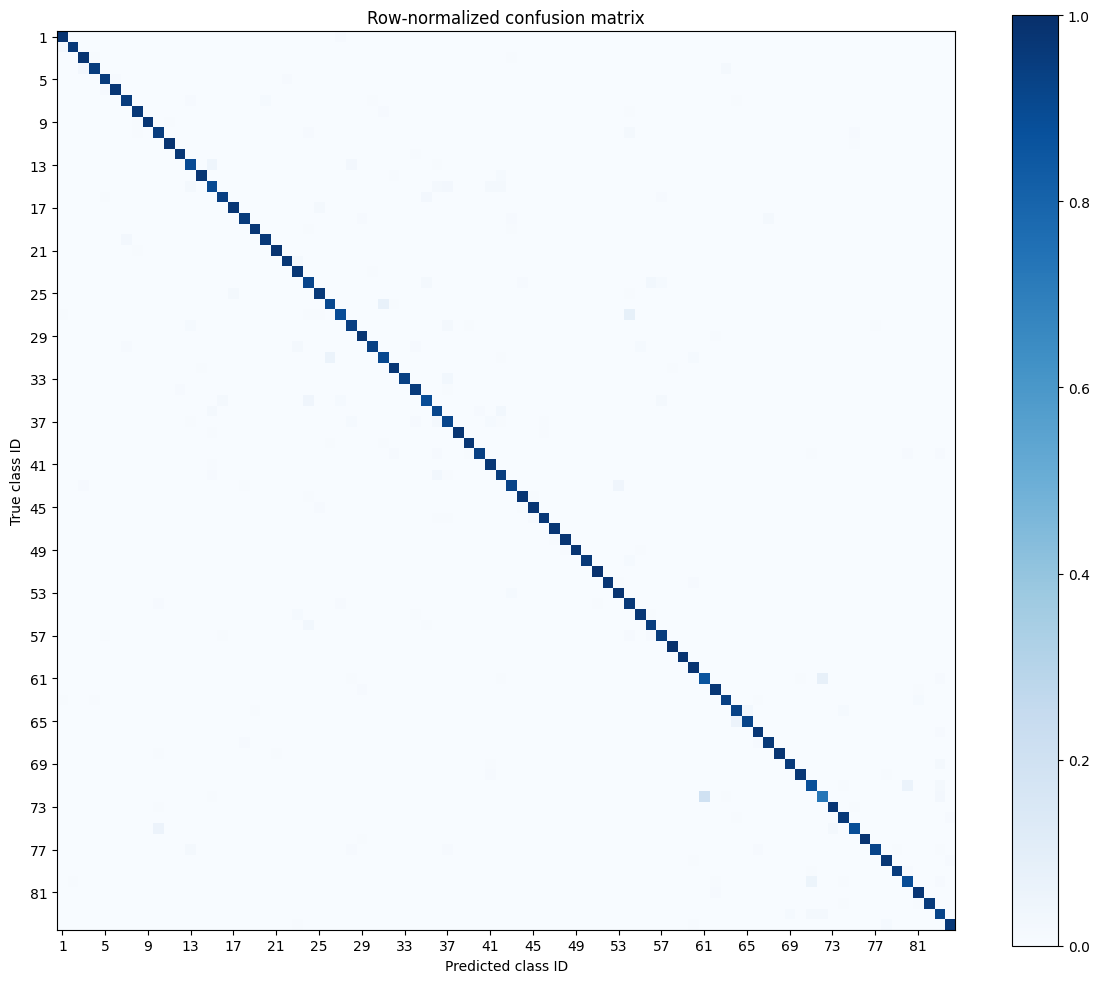

loss                           0.620064
accuracy                       0.950206
macro_f1                       0.949986
weighted_f1                    0.950158
model_median_ms                2.317312
model_p95_ms                   2.566289
end_to_end_median_ms           3.810818
end_to_end_p95_ms              4.185167
batch1_images_per_second     262.410852
benchmark_device                   cuda
benchmark_precision                FP32
parameters                     11219604
artifact_mb                   42.872874
test_images                       24782
best_epoch                           29
training_seconds            4278.910241
dtype: object

,precision,recall,f1-score,support
class_01,0.954248,0.983165,0.968491,297.000000
class_02,0.993031,0.962838,0.977702,296.000000
class_03,0.950820,0.983051,0.966667,295.000000
class_04,0.978947,0.945763,0.962069,295.000000
class_05,0.949495,0.955932,0.952703,295.000000
...,...,...,...,...
class_83,0.885246,0.921502,0.903010,293.000000
class_84,0.965986,0.962712,0.964346,295.000000
accuracy,0.950206,0.950206,0.950206,0.950206
macro avg,0.950441,0.950032,0.949986,24782.000000


In [67]:
# Evaluate the best validation checkpoint on the held-out test forms.
metrics, report = evaluate_saved_model(
    character_artifacts['resnet18'], char_frame, DATASET_DIR, CHAR_CACHE,
)

character_metrics['resnet18'] = metrics
display(pd.Series(metrics))
display(report)


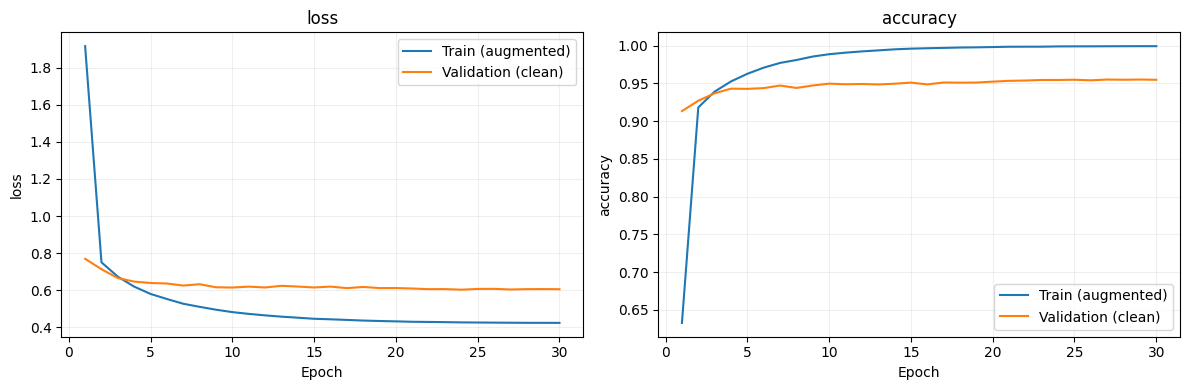

In [68]:
# Compare training/validation behavior and keep the graph with the experiment.
folder = character_artifacts['resnet18'].parent
plot_learning(folder, 'character')

with mlflow.start_run(run_id=read_checkpoint(folder)['run_id']):
    mlflow.log_artifact(str(folder / 'training_curves.png'))

gc.collect()
if DEVICE.type == 'mps':
    torch.mps.empty_cache()


**efficientnet_b0: train → evaluate → learning curves**


In [69]:
# All encoder layers fine-tune; completed runs load without repeating training.
character_artifacts['efficientnet_b0'] = train_model(
    'efficientnet_b0', 'character', char_frame, DATASET_DIR, cache=CHAR_CACHE,
)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /kaggle/working/cache/torch/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 154MB/s]


character/efficientnet_b0 epoch 1:   0%|          | 0/1802 [00:00<?, ?it/s]

{'epoch': 1, 'training_seconds': 240.7714159690022, 'train_loss': 2.506999968516704, 'train_accuracy': 0.49351223827779417, 'val_loss': 0.9205695097446538, 'val_accuracy': 0.8704986430104914, 'val_macro_f1': 0.8694770026245671, 'encoder_lr': 5e-05}


character/efficientnet_b0 epoch 2:   0%|          | 0/1802 [00:00<?, ?it/s]

{'epoch': 2, 'training_seconds': 480.7003939449751, 'train_loss': 0.8249053666148572, 'train_accuracy': 0.8943136676670078, 'val_loss': 0.7116366778075026, 'val_accuracy': 0.9232389516749706, 'val_macro_f1': 0.9229876771961644, 'encoder_lr': 0.0001}


... (45 outputs left out)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=10000.0 (msgs/sec)
ServerApp.rate_limit_window=1.0 (secs)



{'epoch': 29, 'training_seconds': 6961.970156348747, 'train_loss': 0.4448676988587681, 'train_accuracy': 0.9959668326192169, 'val_loss': 0.6060131322887509, 'val_accuracy': 0.9514724348847572, 'val_macro_f1': 0.9510842938225517, 'encoder_lr': 5.299001261011042e-06}


character/efficientnet_b0 epoch 30:   0%|          | 0/1802 [00:00<?, ?it/s]

{'epoch': 30, 'training_seconds': 7203.015884723587, 'train_loss': 0.44419201391846325, 'train_accuracy': 0.9965219352264645, 'val_loss': 0.6053571741732685, 'val_accuracy': 0.9515939563332928, 'val_macro_f1': 0.951255506261095, 'encoder_lr': 5.000000092074153e-06}


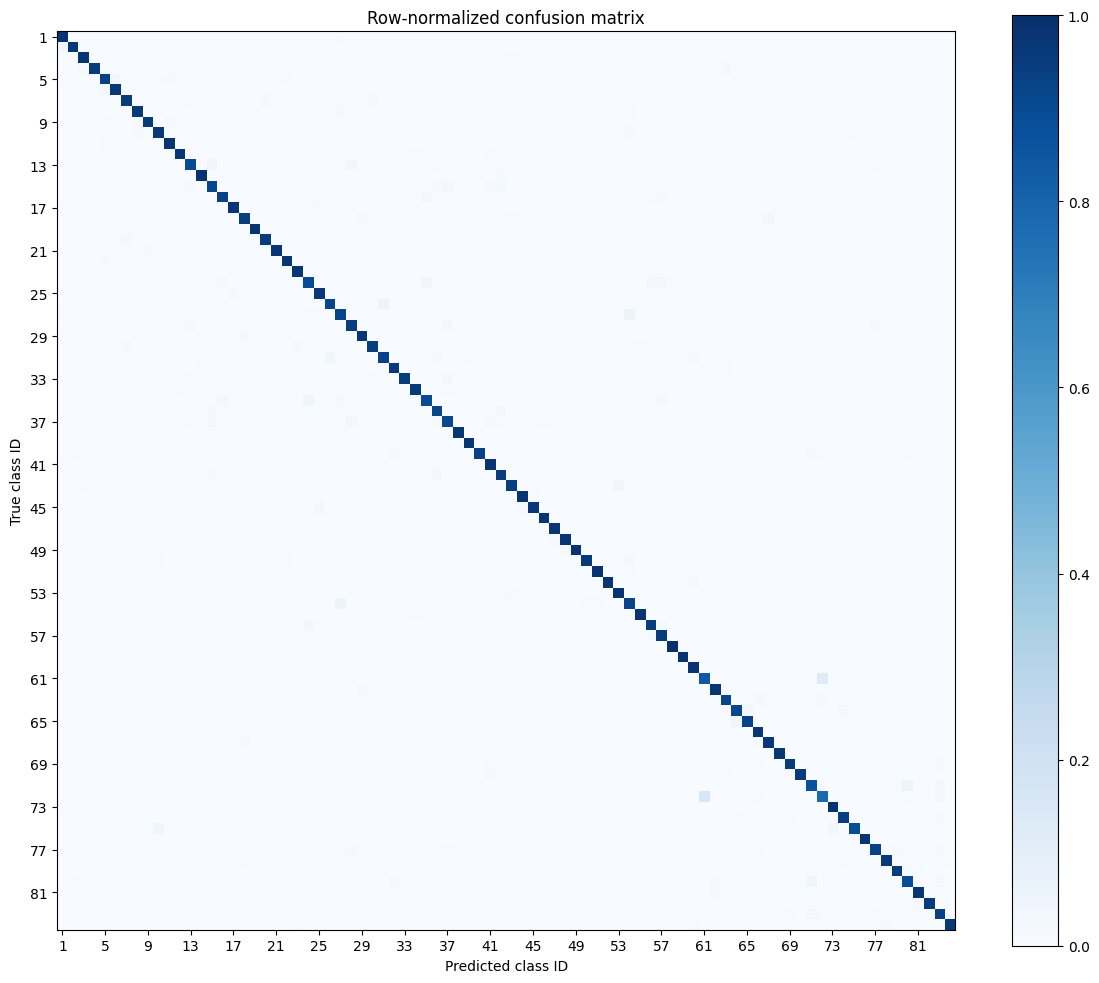

loss                           0.616448
accuracy                        0.94956
macro_f1                        0.94939
weighted_f1                    0.949552
model_median_ms                8.632515
model_p95_ms                    9.43139
end_to_end_median_ms           9.916344
end_to_end_p95_ms             10.621527
batch1_images_per_second     100.843622
benchmark_device                   cuda
benchmark_precision                FP32
parameters                      4115152
artifact_mb                   15.965518
test_images                       24782
best_epoch                           23
training_seconds            7203.015885
dtype: object

,precision,recall,f1-score,support
class_01,0.951140,0.983165,0.966887,297.00000
class_02,0.986207,0.966216,0.976109,296.00000
class_03,0.969900,0.983051,0.976431,295.00000
class_04,0.975779,0.955932,0.965753,295.00000
class_05,0.938567,0.932203,0.935374,295.00000
...,...,...,...,...
class_83,0.880645,0.931741,0.905473,293.00000
class_84,0.982639,0.959322,0.970840,295.00000
accuracy,0.949560,0.949560,0.949560,0.94956
macro avg,0.949680,0.949389,0.949390,24782.00000


In [70]:
# Evaluate the best validation checkpoint on the held-out test forms.
metrics, report = evaluate_saved_model(
    character_artifacts['efficientnet_b0'], char_frame, DATASET_DIR, CHAR_CACHE,
)

character_metrics['efficientnet_b0'] = metrics
display(pd.Series(metrics))
display(report)


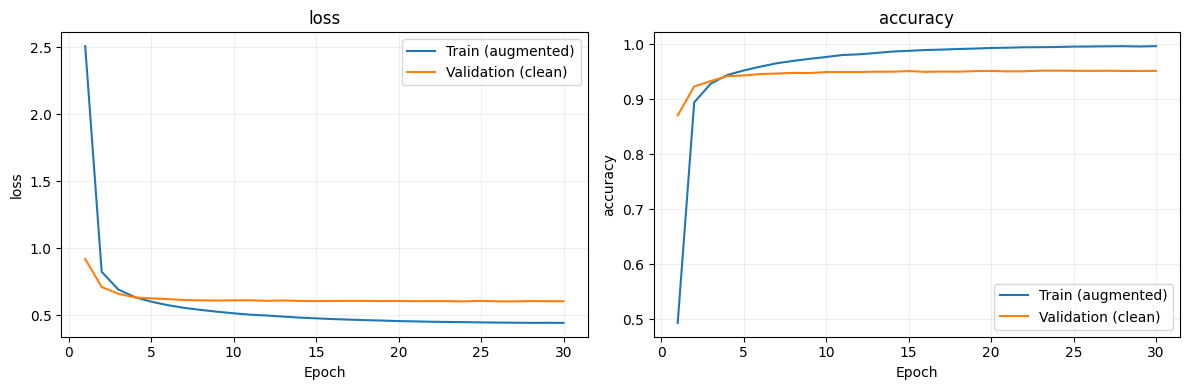

In [71]:
# Compare training/validation behavior and keep the graph with the experiment.
folder = character_artifacts['efficientnet_b0'].parent
plot_learning(folder, 'character')

with mlflow.start_run(run_id=read_checkpoint(folder)['run_id']):
    mlflow.log_artifact(str(folder / 'training_curves.png'))

gc.collect()
if DEVICE.type == 'mps':
    torch.mps.empty_cache()


## 10. Compare and save the best character encoder


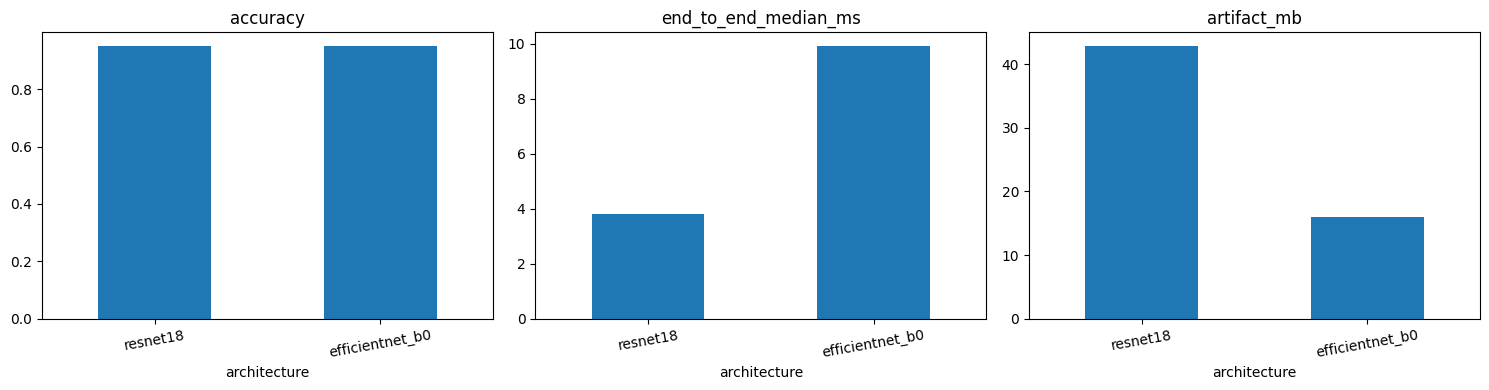

,architecture,validation_score,accuracy,macro_f1,weighted_f1,best_epoch,parameters,artifact_mb,training_seconds,model_median_ms,end_to_end_median_ms,end_to_end_p95_ms
0,resnet18,0.954642,0.950206,0.949986,0.950158,29,11219604,42.872874,4278.910241,2.317312,3.810818,4.185167
1,efficientnet_b0,0.951781,0.949560,0.949390,0.949552,23,4115152,15.965518,7203.015885,8.632515,9.916344,10.621527


Saved character-pretraining model: /kaggle/working/training_runs/macos_resnet18_efficientnetb0_v1/selected/character/best_model.pt


In [72]:
character_comparison, best_character_path = compare_models(
    list(character_artifacts.values()), 'character',
)

columns = ['architecture', 'validation_score', 'accuracy', 'macro_f1', 'weighted_f1',
           'best_epoch', 'parameters', 'artifact_mb', 'training_seconds',
           'model_median_ms', 'end_to_end_median_ms', 'end_to_end_p95_ms']

display(character_comparison[columns])
print('Saved character-pretraining model:', best_character_path)


In [82]:
# Review MLflow runs from the same local experiment store.
mlflow.set_tracking_uri((EXPERIMENT_DIR / 'mlruns').resolve().as_uri())
experiments = mlflow.search_experiments()
runs = mlflow.search_runs(experiment_ids=[item.experiment_id for item in experiments])

columns = [name for name in [
    'run_id', 'status', 'params.architecture', 'params.task',
    'metrics.val_macro_f1', 'metrics.val_cer', 'metrics.test_accuracy', 'metrics.test_cer',
] if name in runs]

display(runs[columns])
runs.to_csv(EXPERIMENT_DIR / 'mlflow_runs.csv', index=False)


,run_id,status,params.architecture,params.task,metrics.val_macro_f1,metrics.test_accuracy
0,4a22b8fe39af406895d6b5c5402a91c7,FINISHED,efficientnet_b0,character,0.951256,0.949560
1,66e9b24228d5434bad9fa7daf92a9db8,FINISHED,resnet18,character,0.954291,0.950206


In [ ]:
# Keep the character-only model package and training status.
status = {
    'task': 'character',
    'best_character_model': str(best_character_path.relative_to(EXPERIMENT_DIR)),
    'character_architectures': ['resnet18', 'efficientnet_b0'],
    'inference_notebook': '04_hybrid_word_recognition.ipynb',
}
save_json(status, EXPERIMENT_DIR / 'training_status.json')

shutil.make_archive(str(EXPERIMENT_DIR / 'selected_models'), 'zip', EXPERIMENT_DIR / 'selected')
print('Selected character model:', best_character_path)
